# Candidatos à Presidência: receitas, despesas e doadores (DivulgaCandContas / TSE)

Coleta, para cada ano de eleição federal escolhido, **todos os candidatos a Presidente** e suas contas de campanha, e guarda tudo num banco **SQLite** pronto para consulta e cruzamento.

| Dado | Endpoint | Tabela |
|---|---|---|
| Nome, número, partido, gênero, nascimento | `/candidatura/listar` + `/candidatura/buscar` | `candidatos` |
| Receita total e por origem | `/prestador/consulta` → `dadosConsolidados` | `financeiro_resumo` |
| Despesas por categoria | `/prestador/consulta` → `concentracaoDespesas` | `despesas_categoria` |
| Ranking de doadores | `/prestador/consulta` → `rankingDoadores` | `doadores` |

**Arquitetura** (pacote `divulgacand/`, gerado pelas células abaixo):

```
config.py     constantes (URL, código do cargo, "BR")
client.py     cliente HTTP: retry, cache em disco do JSON bruto
parsers.py    JSON bruto -> linhas das tabelas (funções puras)
storage.py    esquema SQLite, upsert, views, leitura em pandas, export CSV
collector.py  orquestra a coleta por ano
analysis.py   consultas prontas (DataFrames)
```

**Como usar:** rode as células em ordem. Só a seção *2. Parâmetros* precisa ser editada. A coleta é **incremental e com cache**: reexecutar não baixa de novo o que já foi baixado.

## 0. Preparação

In [1]:
# Dependências (descomente se necessário):
# %pip install requests pandas matplotlib

from pathlib import Path
import importlib, logging
import pandas as pd

Path("divulgacand").mkdir(exist_ok=True)   # onde os módulos serão gravados
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 200

## 1. Módulos

Cada célula grava um módulo em `divulgacand/`. Depois de gravados, podem ser usados em qualquer outro script ou notebook (`from divulgacand import ...`). Se você editar um módulo, reinicie o kernel (ou use `%load_ext autoreload` / `%autoreload 2`).

In [4]:
%%writefile divulgacand/config.py
"""Constantes do projeto."""
from pathlib import Path

BASE_URL = "https://divulgacandcontas.tse.jus.br/divulga/rest/v1"

# Código do cargo de Presidente da República na API
CARGO_PRESIDENTE = 1

# Em eleições federais o "município" da URL é a sigla BR
UF_BRASIL = "BR"

DEFAULT_DATA_DIR = Path("data")

Overwriting divulgacand/config.py


In [ ]:
%%writefile divulgacand/client.py
"""Cliente HTTP da API DivulgaCandContas.

- Um método por endpoint usado no projeto.
- Retry com backoff para erros transitórios (429/5xx).
- Cache em disco das respostas brutas (JSON): reexecutar o notebook não
  volta a bater na API, e é possível reprocessar os dados sem rede.
- 404 e respostas vazias viram `None` (e também são cacheados).
"""

from __future__ import annotations

import json
import logging
import time
from pathlib import Path

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from .config import BASE_URL, CARGO_PRESIDENTE, DEFAULT_DATA_DIR, UF_BRASIL

log = logging.getLogger(__name__)


class APIError(RuntimeError):
    """Erro não recuperável ao consultar a API."""


class DivulgaCandClient:
    def __init__(self, base_url: str = BASE_URL, cache_dir=DEFAULT_DATA_DIR / "cache",
                 use_cache: bool = True, refresh: bool = False, pause: float = 0.3,
                 timeout: float = 30, session=None):
        """
        use_cache : lê/grava respostas brutas em `cache_dir`.
        refresh   : ignora o cache existente e baixa de novo (sobrescrevendo-o).
        pause     : espera (s) após cada requisição real, para não sobrecarregar o TSE.
        session   : qualquer objeto com `.get(url, timeout=)`; útil em testes.
        """
        self.base_url = base_url.rstrip("/")
        self.cache_dir = Path(cache_dir)
        self.use_cache = use_cache
        self.refresh = refresh
        self.pause = pause
        self.timeout = timeout
        self.session = session or self._build_session()
        if use_cache:
            self.cache_dir.mkdir(parents=True, exist_ok=True)

    @staticmethod
    def _build_session() -> requests.Session:
        s = requests.Session()
        retry = Retry(total=5, backoff_factor=1.0, status_forcelist=(429, 500, 502, 503, 504),
                      allowed_methods=("GET",))
        s.mount("https://", HTTPAdapter(max_retries=retry))
        s.headers.update({
            "User-Agent": "Mozilla/5.0 (compatible; divulgacand-notebook/1.0)",
            "Accept": "application/json",
        })
        return s

    # ------------------------------------------------------------------ núcleo
    def _cache_file(self, path: str) -> Path:
        return self.cache_dir / (path.strip("/").replace("/", "__") + ".json")

    def _get(self, path: str):
        cache_file = self._cache_file(path)
        if self.use_cache and not self.refresh and cache_file.exists():
            return json.loads(cache_file.read_text(encoding="utf-8"))["data"]

        url = self.base_url + path
        log.debug("GET %s", url)
        resp = self.session.get(url, timeout=self.timeout)

        if resp.status_code == 404:
            data = None
        elif resp.status_code == 200:
            try:
                data = resp.json()
            except ValueError:
                log.warning("Resposta 200 sem JSON válido em %s", url)
                data = None
        else:
            raise APIError(f"HTTP {resp.status_code} em {url}")

        if self.use_cache:
            cache_file.write_text(json.dumps({"url": url, "data": data}, ensure_ascii=False),
                                  encoding="utf-8")
        if self.pause:
            time.sleep(self.pause)
        return data

    # --------------------------------------------------------------- endpoints
    def anos_eleitorais(self) -> list:
        """GET /eleicao/anos-eleitorais"""
        return self._get("/eleicao/anos-eleitorais") or []

    def eleicoes_ordinarias(self) -> list:
        """GET /eleicao/ordinarias"""
        return self._get("/eleicao/ordinarias") or []

    def listar_candidatos(self, ano: int, eleicao: int, cargo: int = CARGO_PRESIDENTE,
                          municipio: str = UF_BRASIL):
        """GET /candidatura/listar/{ano}/{municipio}/{eleicao}/{cargo}/candidatos"""
        return self._get(f"/candidatura/listar/{ano}/{municipio}/{eleicao}/{cargo}/candidatos")

    def buscar_candidato(self, ano: int, eleicao: int, candidato: int, municipio: str = UF_BRASIL):
        """GET /candidatura/buscar/{ano}/{municipio}/{eleicao}/candidato/{candidato}"""
        return self._get(f"/candidatura/buscar/{ano}/{municipio}/{eleicao}/candidato/{candidato}")

    def consultar_prestador(self, ano: int, eleicao: int, candidato: int,
                            cargo: int = CARGO_PRESIDENTE, municipio: str = UF_BRASIL):
        """GET /prestador/consulta/{eleicao}/{ano}/{municipio}/{cargo}/90/90/{candidato}"""
        return self._get(f"/prestador/consulta/{eleicao}/{ano}/{municipio}/{cargo}/90/90/{candidato}")

Writing divulgacand/client.py


In [4]:
%%writefile divulgacand/parsers.py
"""Funções puras que transformam o JSON bruto da API em linhas (dicts) prontas
para as tabelas. Não fazem I/O, o que facilita testar e reaproveitar."""
from __future__ import annotations

import re
from datetime import datetime, timedelta, timezone


# ----------------------------------------------------------------- utilitários
def to_float(x):
    if x is None or x == "":
        return None
    try:
        return float(x)
    except (TypeError, ValueError):
        try:  # formato brasileiro "1.234,56"
            return float(str(x).replace(".", "").replace(",", "."))
        except ValueError:
            return None


def to_int(x):
    f = to_float(x)
    return None if f is None else int(f)


def ms_to_date(ms):
    """Epoch em milissegundos -> 'AAAA-MM-DD'.

    A API entrega a data de nascimento como timestamp. Somamos 12h antes de
    truncar para a data, o que torna o resultado independente de o timestamp
    representar meia-noite em UTC ou em horário local (fusos de -12h a +12h).
    Aceita valores negativos (nascidos antes de 1970).
    """
    ms = to_int(ms)
    if ms is None:
        return None
    dt = datetime(1970, 1, 1, tzinfo=timezone.utc) + timedelta(milliseconds=ms, hours=12)
    return dt.date().isoformat()


def tipo_pessoa(cpf_cnpj):
    """'PF' ou 'PJ' pelo tamanho do documento (funciona mesmo com CPF mascarado)."""
    if not cpf_cnpj:
        return None
    n = len(re.sub(r"[.\-/\s]", "", str(cpf_cnpj)))
    return "PJ" if n >= 14 else "PF" if n == 11 else None


# ------------------------------------------------------------------- eleições
def parse_eleicao(e: dict) -> dict:
    return {
        "id_eleicao": to_int(e.get("id")),
        "ano": to_int(e.get("ano")),
        "nome": e.get("nomeEleicao") or e.get("descricaoEleicao"),
        "turno": e.get("turno"),
        "tipo": e.get("tipoEleicao"),
        # o swagger grafa "tipoAbragencia"; a API real costuma usar "tipoAbrangencia"
        "abrangencia": e.get("tipoAbrangencia") or e.get("tipoAbragencia"),
        "data_eleicao": e.get("dataEleicao"),
    }


# ----------------------------------------------------------------- candidatos
def parse_candidato(lista: dict | None, detalhe: dict | None, ano: int, id_eleicao: int,
                    turno=None) -> dict:
    """Une o item da listagem com o detalhe do candidato (o detalhe prevalece,
    exceto quando vier nulo)."""
    m = dict(lista or {})
    m.update({k: v for k, v in (detalhe or {}).items() if v is not None})

    partido = m.get("partido") or {}
    cargo = m.get("cargo") or {}
    nasc = ms_to_date(m.get("dataDeNascimento"))
    # idade aproximada: referência 1º de outubro (eleições ocorrem no início de outubro)
    idade = None
    if nasc:
        y, mo, d = map(int, nasc.split("-"))
        idade = ano - y - ((mo, d) > (10, 1))

    return {
        "id_eleicao": id_eleicao,
        "id_candidato": to_int(m.get("id")),
        "ano": ano,
        "turno": turno,
        "nome_completo": m.get("nomeCompleto"),
        "nome_urna": m.get("nomeUrna"),
        "numero": to_int(m.get("numero")),
        "sigla_partido": partido.get("sigla") or m.get("siglaPartido"),
        "nome_partido": partido.get("nome") or m.get("nomePartido"),
        "numero_partido": to_int(partido.get("numero")),
        "genero": m.get("descricaoSexo"),
        "data_nascimento": nasc,
        "idade_na_eleicao": idade,
        "cargo": cargo.get("nome"),
        "situacao": m.get("descricaoSituacao"),
        "totalizacao": m.get("descricaoTotalizacao"),
        "coligacao": m.get("nomeColigacao"),
        "composicao_coligacao": m.get("composicaoColigacao"),
        "grau_instrucao": m.get("grauInstrucao"),
        "ocupacao": m.get("ocupacao"),
        "estado_civil": m.get("descricaoEstadoCivil"),
        "cor_raca": m.get("descricaoCorRaca"),
        "uf_nascimento": m.get("sgUfNascimento"),
        "municipio_nascimento": m.get("nomeMunicipioNascimento"),
        "nacionalidade": m.get("nacionalidade"),
        "reeleicao": None if m.get("st_REELEICAO") is None else int(bool(m["st_REELEICAO"])),
    }


# ----------------------------------------------------------------- prestação
def parse_prestador(raw: dict | None, ano: int, id_eleicao: int, id_candidato: int):
    """Retorna (resumo, despesas, doadores):
    - resumo   : dict (1 linha) com receitas consolidadas e totais de despesa
    - despesas : lista de dicts, uma por categoria de despesa
    - doadores : lista de dicts, um por doador, já ranqueados por valor
    Retorna (None, [], []) se não houver prestação de contas."""
    if not raw:
        return None, [], []
    chave = {"id_eleicao": id_eleicao, "id_candidato": id_candidato, "ano": ano}
    dc = raw.get("dadosConsolidados") or {}
    dp = raw.get("despesas") or {}

    resumo = {
        **chave,
        "total_recebido": to_float(dc.get("totalRecebido")),
        "qtd_receitas": to_int(dc.get("qtdRecebido")),
        "receita_financeira": to_float(dc.get("totalFinanceiro")),
        "receita_estimada": to_float(dc.get("totalEstimados")),
        "receita_pessoa_fisica": to_float(dc.get("totalReceitaPF")),
        "receita_pessoa_juridica": to_float(dc.get("totalReceitaPJ")),
        "receita_partidos": to_float(dc.get("totalPartidos")),
        "receita_internet": to_float(dc.get("totalInternet")),
        "receita_recursos_proprios": to_float(dc.get("totalProprios")),
        "receita_outros_candidatos": to_float(dc.get("totalReceitaOutCand")),
        "receita_fcc": to_float(dc.get("totalDoacaoFcc")),
        "fundo_partidario": to_float(dp.get("fundosPartidarios")),
        "fundo_especial_fefc": to_float(dp.get("fundoEspecial")),
        "outros_recursos": to_float(dp.get("outrosRecursos")),
        "limite_gastos": to_float(dp.get("valorLimiteDeGastos") or dp.get("limiteDeGasto1T")),
        "despesas_contratadas": to_float(dp.get("totalDespesasContratadas")),
        "despesas_pagas": to_float(dp.get("totalDespesasPagas")),
        "data_atualizacao_contas": raw.get("dataUltimaAtualizacaoContas"),
        "cnpj_campanha": raw.get("cnpj"),
    }

    # --- despesas por categoria (somando duplicatas de categoria, se houver)
    por_cat: dict[str, dict] = {}
    for d in raw.get("concentracaoDespesas") or []:
        cat = (d.get("dsDRD") or "Não informado").strip()
        acc = por_cat.setdefault(cat, {"qtd_despesas": 0, "valor": 0.0})
        acc["qtd_despesas"] += to_int(d.get("qtdeDespesas")) or 0
        acc["valor"] += to_float(d.get("valor")) or 0.0
    total = sum(v["valor"] for v in por_cat.values())
    despesas = [
        {**chave, "categoria": cat, "qtd_despesas": v["qtd_despesas"], "valor": v["valor"],
         "percentual": round(100 * v["valor"] / total, 4) if total else None}
        for cat, v in sorted(por_cat.items(), key=lambda kv: -kv[1]["valor"])
    ]

    # --- ranking de doadores
    brutos = sorted(raw.get("rankingDoadores") or [], key=lambda r: -(to_float(r.get("valor")) or 0))
    doadores = [
        {**chave, "posicao": i, "cpf_cnpj": r.get("cpfCnpj"), "nome": r.get("nome"),
         "tipo_pessoa": tipo_pessoa(r.get("cpfCnpj")), "qtd_doacoes": to_int(r.get("qntd")),
         "valor": to_float(r.get("valor")),
         "financiamento_coletivo": None if r.get("stFinanciamentoColetivo") is None
         else int(bool(r["stFinanciamentoColetivo"]))}
        for i, r in enumerate(brutos, start=1)
    ]
    return resumo, despesas, doadores

Writing divulgacand/parsers.py


In [5]:
%%writefile divulgacand/storage.py
"""Persistência em SQLite (arquivo único, sem servidor) + leitura em pandas.

Modelo relacional (chaves: id_eleicao + id_candidato):

  eleicoes ──< candidatos ──1:1── financeiro_resumo
                   ├──< despesas_categoria
                   ├──< doadores
                   └──< coleta_log

Duas views já prontas para cruzamento:
  vw_candidatos_financeiro : candidato + resumo financeiro
  vw_doadores_candidatos   : doador + dados do candidato beneficiado
"""
from __future__ import annotations

import sqlite3
from datetime import datetime
from pathlib import Path

import pandas as pd

# tabela -> (colunas {nome: tipo SQL}, chave primária)
SCHEMA = {
    "eleicoes": ({
        "id_eleicao": "INTEGER", "ano": "INTEGER", "nome": "TEXT", "turno": "TEXT",
        "tipo": "TEXT", "abrangencia": "TEXT", "data_eleicao": "TEXT",
    }, ["id_eleicao"]),

    "candidatos": ({
        "id_eleicao": "INTEGER", "id_candidato": "INTEGER", "ano": "INTEGER", "turno": "TEXT",
        "nome_completo": "TEXT", "nome_urna": "TEXT", "numero": "INTEGER",
        "sigla_partido": "TEXT", "nome_partido": "TEXT", "numero_partido": "INTEGER",
        "genero": "TEXT", "data_nascimento": "TEXT", "idade_na_eleicao": "INTEGER",
        "cargo": "TEXT", "situacao": "TEXT", "totalizacao": "TEXT", "coligacao": "TEXT",
        "composicao_coligacao": "TEXT", "grau_instrucao": "TEXT", "ocupacao": "TEXT",
        "estado_civil": "TEXT", "cor_raca": "TEXT", "uf_nascimento": "TEXT",
        "municipio_nascimento": "TEXT", "nacionalidade": "TEXT", "reeleicao": "INTEGER",
    }, ["id_eleicao", "id_candidato"]),

    "financeiro_resumo": ({
        "id_eleicao": "INTEGER", "id_candidato": "INTEGER", "ano": "INTEGER",
        "total_recebido": "REAL", "qtd_receitas": "INTEGER", "receita_financeira": "REAL",
        "receita_estimada": "REAL", "receita_pessoa_fisica": "REAL",
        "receita_pessoa_juridica": "REAL", "receita_partidos": "REAL",
        "receita_internet": "REAL", "receita_recursos_proprios": "REAL",
        "receita_outros_candidatos": "REAL", "receita_fcc": "REAL",
        "fundo_partidario": "REAL", "fundo_especial_fefc": "REAL", "outros_recursos": "REAL",
        "limite_gastos": "REAL", "despesas_contratadas": "REAL", "despesas_pagas": "REAL",
        "data_atualizacao_contas": "TEXT", "cnpj_campanha": "TEXT",
    }, ["id_eleicao", "id_candidato"]),

    "despesas_categoria": ({
        "id_eleicao": "INTEGER", "id_candidato": "INTEGER", "ano": "INTEGER",
        "categoria": "TEXT", "qtd_despesas": "INTEGER", "valor": "REAL", "percentual": "REAL",
    }, ["id_eleicao", "id_candidato", "categoria"]),

    "doadores": ({
        "id_eleicao": "INTEGER", "id_candidato": "INTEGER", "ano": "INTEGER",
        "posicao": "INTEGER", "cpf_cnpj": "TEXT", "nome": "TEXT", "tipo_pessoa": "TEXT",
        "qtd_doacoes": "INTEGER", "valor": "REAL", "financiamento_coletivo": "INTEGER",
    }, ["id_eleicao", "id_candidato", "posicao"]),

    "coleta_log": ({
        "id_eleicao": "INTEGER", "id_candidato": "INTEGER", "ano": "INTEGER",
        "etapa": "TEXT", "status": "TEXT", "detalhe": "TEXT", "coletado_em": "TEXT",
    }, ["id_eleicao", "id_candidato", "etapa"]),
}

VIEWS = {
    "vw_candidatos_financeiro": """
        SELECT c.*, f.total_recebido, f.receita_financeira, f.receita_estimada,
               f.receita_pessoa_fisica, f.receita_pessoa_juridica, f.receita_partidos,
               f.receita_internet, f.receita_recursos_proprios, f.receita_outros_candidatos,
               f.fundo_partidario, f.fundo_especial_fefc, f.limite_gastos,
               f.despesas_contratadas, f.despesas_pagas
        FROM candidatos c
        LEFT JOIN financeiro_resumo f USING (id_eleicao, id_candidato)""",
    "vw_doadores_candidatos": """
        SELECT d.*, c.nome_urna, c.nome_completo, c.sigla_partido, c.numero, c.turno
        FROM doadores d
        JOIN candidatos c USING (id_eleicao, id_candidato)""",
}


class SQLiteRepository:
    def __init__(self, path="data/eleicoes.db"):
        self.path = Path(path)
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.conn = sqlite3.connect(self.path)
        self._create()

    # ------------------------------------------------------------------ DDL
    def _create(self):
        for table, (cols, pk) in SCHEMA.items():
            col_sql = ", ".join(f"{c} {t}" for c, t in cols.items())
            self.conn.execute(
                f"CREATE TABLE IF NOT EXISTS {table} ({col_sql}, PRIMARY KEY ({', '.join(pk)}))")
        for view, sql in VIEWS.items():
            self.conn.execute(f"CREATE VIEW IF NOT EXISTS {view} AS {sql}")
        self.conn.commit()

    # ------------------------------------------------------------- escrita
    def upsert(self, table: str, rows):
        """INSERT OR REPLACE; colunas ausentes no dict viram NULL."""
        if isinstance(rows, dict):
            rows = [rows]
        if not rows:
            return
        cols = list(SCHEMA[table][0])
        sql = (f"INSERT OR REPLACE INTO {table} ({', '.join(cols)}) "
               f"VALUES ({', '.join('?' for _ in cols)})")
        self.conn.executemany(sql, [tuple(r.get(c) for c in cols) for r in rows])

    def clear_candidate(self, id_eleicao: int, id_candidato: int):
        """Remove linhas filhas antes de regravar, para que reexecuções não deixem
        categorias/doadores antigos para trás."""
        for t in ("despesas_categoria", "doadores", "financeiro_resumo"):
            self.conn.execute(f"DELETE FROM {t} WHERE id_eleicao=? AND id_candidato=?",
                              (id_eleicao, id_candidato))

    def log(self, id_eleicao, id_candidato, ano, etapa, status, detalhe=None):
        self.upsert("coleta_log", {
            "id_eleicao": id_eleicao, "id_candidato": id_candidato, "ano": ano, "etapa": etapa,
            "status": status, "detalhe": detalhe,
            "coletado_em": datetime.now().isoformat(timespec="seconds")})

    def commit(self):
        self.conn.commit()

    # -------------------------------------------------------------- leitura
    def read(self, table_or_sql: str, params=()) -> pd.DataFrame:
        """Aceita um nome de tabela/view ou uma consulta SQL completa."""
        sql = table_or_sql if " " in table_or_sql.strip() else f"SELECT * FROM {table_or_sql}"
        return pd.read_sql_query(sql, self.conn, params=params)

    def tables(self) -> pd.DataFrame:
        """Resumo do conteúdo: tabelas/views e número de linhas."""
        nomes = [r[0] for r in self.conn.execute(
            "SELECT name FROM sqlite_master WHERE type IN ('table','view') ORDER BY type DESC, name")]
        return pd.DataFrame({
            "nome": nomes,
            "linhas": [self.conn.execute(f"SELECT COUNT(*) FROM {n}").fetchone()[0] for n in nomes]})

    def export_csv(self, out_dir="data/csv"):
        out = Path(out_dir)
        out.mkdir(parents=True, exist_ok=True)
        paths = []
        for name in list(SCHEMA) + list(VIEWS):
            p = out / f"{name}.csv"
            self.read(name).to_csv(p, index=False, encoding="utf-8-sig")
            paths.append(p)
        return paths

    def close(self):
        self.conn.close()

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        self.close()

Writing divulgacand/storage.py


In [ ]:
%%writefile divulgacand/collector.py
"""Orquestra a coleta: descobre as eleições federais de cada ano, baixa
candidatos a presidente, suas contas de campanha, e grava tudo no repositório."""
from __future__ import annotations

import logging

from . import parsers
from .config import CARGO_PRESIDENTE, UF_BRASIL

log = logging.getLogger(__name__)


def _abrangencia(e: dict) -> str:
    return str(e.get("tipoAbrangencia") or e.get("tipoAbragencia") or "").upper()


def descobrir_eleicoes(client, ano: int, ordinarias: list | None = None) -> list[dict]:
    """Eleições ordinárias de `ano` que podem conter candidatos a presidente.

    Prefere as de abrangência federal (F). Se a API não informar a abrangência,
    testa todas as eleições do ano.
    """
    ordinarias = ordinarias if ordinarias is not None else client.eleicoes_ordinarias()
    do_ano = [e for e in ordinarias if parsers.to_int(e.get("ano")) == ano]
    federais = [e for e in do_ano if _abrangencia(e).startswith("F")]
    return federais or do_ano


def collect(anos, client, repo, cargo: int = CARGO_PRESIDENTE, eleicao_ids: dict | None = None,
            incluir_financeiro: bool = True) -> dict:
    """Coleta os candidatos de `cargo` (padrão: Presidente) para cada ano em `anos`.

    anos        : iterável de anos eleitorais (ex.: [2014, 2018, 2022]).
    eleicao_ids : opcional, {ano: [id_eleicao, ...]} para forçar quais eleições usar
                  (útil se a descoberta automática não servir).
    Retorna um dict {ano: {"eleicoes": n, "candidatos": n, "com_contas": n, "erros": n}}.
    Falhas em um candidato são registradas em `coleta_log` e não interrompem o resto.
    """
    ordinarias = client.eleicoes_ordinarias()
    anos_api = {parsers.to_int(e.get("ano")) for e in ordinarias}
    resumo: dict = {}

    for ano in anos:
        stats = resumo[ano] = {"eleicoes": 0, "candidatos": 0, "com_contas": 0, "erros": 0}
        if ano not in anos_api:
            log.warning("[%s] ano não consta em /eleicao/ordinarias; tentando mesmo assim.", ano)

        if eleicao_ids and ano in eleicao_ids:
            eleicoes = [{"id": i, "ano": ano} for i in eleicao_ids[ano]]
        else:
            eleicoes = descobrir_eleicoes(client, ano, ordinarias)

        for el in eleicoes:
            id_el = parsers.to_int(el.get("id"))
            lista = client.listar_candidatos(ano, id_el, cargo=cargo, municipio=UF_BRASIL)
            candidatos = (lista or {}).get("candidatos") or []
            if not candidatos:
                log.info("[%s] eleição %s: sem candidatos ao cargo %s", ano, id_el, cargo)
                continue

            stats["eleicoes"] += 1
            meta = parsers.parse_eleicao({**el, "ano": ano})
            repo.upsert("eleicoes", meta)
            log.info("[%s] eleição %s (%s, turno %s): %d candidatos", ano, id_el,
                     meta["nome"], meta["turno"], len(candidatos))

            for item in candidatos:
                id_cand = parsers.to_int(item.get("id"))
                num_cand = parsers.to_int(item.get("numero"))
                try:
                    detalhe = client.buscar_candidato(ano, id_el, id_cand)
                    row = parsers.parse_candidato(item, detalhe, ano, id_el, meta["turno"])
                    repo.upsert("candidatos", row)
                    stats["candidatos"] += 1
                    repo.log(id_el, id_cand, ano, "candidato", "ok")

                    if incluir_financeiro:
                        raw = client.consultar_prestador(ano, id_el, id_cand, num_cand, cargo=cargo)
                        res, desp, doad = parsers.parse_prestador(raw, ano, id_el, id_cand)
                        repo.clear_candidate(id_el, id_cand)
                        if res is None:
                            repo.log(id_el, id_cand, ano, "financeiro", "sem_dados",
                                     "API não retornou prestação de contas")
                        else:
                            repo.upsert("financeiro_resumo", res)
                            repo.upsert("despesas_categoria", desp)
                            repo.upsert("doadores", doad)
                            repo.log(id_el, id_cand, ano, "financeiro", "ok",
                                     f"{len(desp)} categorias, {len(doad)} doadores")
                            stats["com_contas"] += 1
                    repo.commit()
                except Exception as exc:  # noqa: BLE001 - registrar e seguir
                    stats["erros"] += 1
                    log.error("[%s] candidato %s: %s", ano, id_cand, exc)
                    repo.log(id_el, id_cand, ano, "erro", "erro", repr(exc))
                    repo.commit()

        if stats["candidatos"] == 0:
            log.warning("[%s] nenhum candidato a presidente encontrado. Esse ano teve eleição "
                        "presidencial? (eleições municipais, por exemplo, não têm)", ano)
    return resumo

Writing divulgacand/collector.py


In [7]:
%%writefile divulgacand/analysis.py
"""Consultas prontas sobre o repositório, devolvendo DataFrames."""
from __future__ import annotations

import pandas as pd


def _in_clause(anos):
    if not anos:
        return "", ()
    return f" WHERE ano IN ({','.join('?' for _ in anos)})", tuple(anos)


def candidatos(repo, anos=None) -> pd.DataFrame:
    """Dados cadastrais básicos (nome, número, partido, gênero, nascimento...)."""
    where, p = _in_clause(anos)
    df = repo.read(f"SELECT ano, turno, id_candidato, nome_urna, nome_completo, numero, "
                   f"sigla_partido, genero, data_nascimento, idade_na_eleicao, situacao, "
                   f"totalizacao FROM candidatos{where} ORDER BY ano, turno, numero", p)
    return df


def panorama(repo, anos=None) -> pd.DataFrame:
    """Candidato + receita total + despesas, numa tabela só (view vw_candidatos_financeiro)."""
    where, p = _in_clause(anos)
    return repo.read(f"SELECT ano, turno, id_candidato, nome_urna, sigla_partido, genero, "
                     f"total_recebido, despesas_contratadas, despesas_pagas, limite_gastos "
                     f"FROM vw_candidatos_financeiro{where} "
                     f"ORDER BY ano, total_recebido DESC", p)


def receita_por_fonte(repo, anos=None) -> pd.DataFrame:
    """Receita por origem (PF, PJ, partidos, recursos próprios, internet), em valor e %.
    Formato largo: uma linha por candidato."""
    where, p = _in_clause(anos)
    df = repo.read(f"SELECT ano, turno, nome_urna, sigla_partido, total_recebido, "
                   f"receita_pessoa_fisica, receita_pessoa_juridica, receita_partidos, "
                   f"receita_recursos_proprios, receita_internet, receita_outros_candidatos, "
                   f"fundo_especial_fefc, fundo_partidario "
                   f"FROM vw_candidatos_financeiro{where}", p)
    df = df[df["total_recebido"].notna() & (df["total_recebido"] > 0)].copy()
    for col in ["receita_pessoa_fisica", "receita_pessoa_juridica", "receita_partidos",
                "receita_recursos_proprios", "receita_internet", "receita_outros_candidatos",
                "fundo_especial_fefc", "fundo_partidario"]:
        df["pct_" + col.removeprefix("receita_")] = (100 * df[col] / df["total_recebido"]).round(2)
    return df.sort_values(["ano", "total_recebido"], ascending=[True, False]).reset_index(drop=True)


def despesas_por_categoria(repo, ano: int, valores: str = "percentual") -> pd.DataFrame:
    """Matriz candidato x categoria de despesa. valores = 'percentual' | 'valor'."""
    df = repo.read("SELECT c.nome_urna, d.categoria, d.valor, d.percentual "
                   "FROM despesas_categoria d JOIN candidatos c USING (id_eleicao, id_candidato) "
                   "WHERE d.ano = ?", (ano,))
    if df.empty:
        return df
    return (df.pivot_table(index="nome_urna", columns="categoria", values=valores,
                           aggfunc="sum", fill_value=0).round(2))


def ranking_doadores(repo, ano: int | None = None, candidato: str | None = None,
                     top: int = 10) -> pd.DataFrame:
    """Top `top` doadores de cada candidato (filtre por ano e/ou nome de urna)."""
    cond, p = [], []
    if ano is not None:
        cond.append("ano = ?"); p.append(ano)
    if candidato:
        cond.append("nome_urna LIKE ?"); p.append(f"%{candidato}%")
    where = (" WHERE " + " AND ".join(cond)) if cond else ""
    df = repo.read(f"SELECT ano, nome_urna, posicao, nome AS doador, cpf_cnpj, tipo_pessoa, "
                   f"qtd_doacoes, valor FROM vw_doadores_candidatos{where} "
                   f"ORDER BY ano, nome_urna, posicao", tuple(p))
    return df[df["posicao"] <= top].reset_index(drop=True)


def doadores_em_comum(repo, ano: int | None = None) -> pd.DataFrame:
    """Doadores que financiaram mais de um candidato (cruzamento por documento + nome).
    Atenção: se a API mascarar CPFs de pessoa física, o cruzamento só é confiável
    para CNPJs e para CPFs não mascarados."""
    where = " WHERE ano = ?" if ano is not None else ""
    p = (ano,) if ano is not None else ()
    df = repo.read(f"SELECT ano, cpf_cnpj, nome AS doador, nome_urna, valor "
                   f"FROM vw_doadores_candidatos{where}", p)
    if df.empty:
        return df
    g = df.groupby(["ano", "cpf_cnpj", "doador"]).agg(
        n_candidatos=("nome_urna", "nunique"),
        candidatos=("nome_urna", lambda s: ", ".join(sorted(set(s)))),
        valor_total=("valor", "sum")).reset_index()
    return g[g["n_candidatos"] > 1].sort_values("valor_total", ascending=False).reset_index(drop=True)


def concentracao_doadores(repo, ano: int | None = None, top: int = 10) -> pd.DataFrame:
    """Quanto da receita de doações rastreadas vem dos `top` maiores doadores
    e índice de Herfindahl-Hirschman (HHI, 0-1) por candidato."""
    where = " WHERE ano = ?" if ano is not None else ""
    p = (ano,) if ano is not None else ()
    df = repo.read(f"SELECT ano, nome_urna, posicao, valor FROM vw_doadores_candidatos{where}", p)
    if df.empty:
        return df
    linhas = []
    for (a, nome), g in df.groupby(["ano", "nome_urna"]):
        total = g["valor"].sum()
        if not total:
            continue
        share = g["valor"] / total
        linhas.append({"ano": a, "nome_urna": nome, "n_doadores": len(g),
                       "total_doado": total,
                       f"pct_top{top}": round(100 * g.nsmallest(top, "posicao")["valor"].sum() / total, 2),
                       "hhi": round(float((share ** 2).sum()), 4)})
    return pd.DataFrame(linhas).sort_values(["ano", "total_doado"], ascending=[True, False]).reset_index(drop=True)

Writing divulgacand/analysis.py


In [8]:
%%writefile divulgacand/__init__.py
"""divulgacand - coleta e análise de dados de candidaturas e contas de campanha
a partir da API do DivulgaCandContas (TSE)."""
from .config import BASE_URL, CARGO_PRESIDENTE, UF_BRASIL
from .client import DivulgaCandClient
from .storage import SQLiteRepository
from .collector import collect
from . import analysis

__all__ = ["BASE_URL", "CARGO_PRESIDENTE", "UF_BRASIL", "DivulgaCandClient",
           "SQLiteRepository", "collect", "analysis"]

Writing divulgacand/__init__.py


## 2. Parâmetros

In [2]:
# IMPORTANTE
# Antes de 2018, as eleições presidenciais não reportavam dados de concentração de despesas.
# As únicas bases usáveis são de 2018 e 2022.
ANOS = [2018, 2022]          # anos de eleições federais a coletar


DB_PATH = "data/eleicoes.db"       # banco SQLite de saída
ATUALIZAR_CACHE = False            # True = ignora o cache e baixa tudo de novo
INCLUIR_FINANCEIRO = True          # False = só dados cadastrais dos candidatos

## 3. Coleta

Antes de coletar, vale conferir quais anos a API disponibiliza. Observação: nem todos os anos têm prestação de contas publicada; o coletor registra no `coleta_log` o que faltou, sem interromper o restante.

In [3]:
import importlib; importlib.invalidate_caches()
from divulgacand import DivulgaCandClient, SQLiteRepository, collect, analysis

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)

client = DivulgaCandClient(refresh=ATUALIZAR_CACHE)
print("Anos eleitorais na API:", sorted(client.anos_eleitorais()))

Anos eleitorais na API: [2004, 2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024, 2026]


In [4]:
repo = SQLiteRepository(DB_PATH)
resumo_coleta = collect(ANOS, client, repo, incluir_financeiro=INCLUIR_FINANCEIRO)
pd.DataFrame(resumo_coleta).T.rename_axis("ano")

[2018] eleição 2022802018 (Eleição Geral Federal 2018, turno None): 14 candidatos
[2022] eleição 2040602022 (Eleição Geral Federal 2022, turno None): 13 candidatos


,eleicoes,candidatos,com_contas,erros
ano,,,,
2018,1,14,14,0
2022,1,13,13,0


### Se a descoberta automática de eleições falhar

O coletor identifica a eleição federal de cada ano via `/eleicao/ordinarias`. Se algum ano vier vazio, descubra o ID correto e force-o:

```python
print(pd.DataFrame(client.eleicoes_ordinarias()).query("ano == 2018"))
collect([2018], client, repo, eleicao_ids={2018: [<id_da_eleicao>]})
```

## 4. Conferência dos dados coletados

In [8]:
display(repo.tables())      # tabelas e views com número de linhas

,nome,linhas
0,vw_candidatos_financeiro,27
1,vw_doadores_candidatos,115
2,candidatos,27
3,coleta_log,54
4,despesas_categoria,448
5,doadores,115
6,eleicoes,2
7,financeiro_resumo,27


In [9]:
# O que deu errado ou ficou sem dados (se vazio, tudo coletado)
repo.read("SELECT ano, id_candidato, etapa, status, detalhe FROM coleta_log WHERE status <> 'ok'")

,ano,id_candidato,etapa,status,detalhe


## 5. Análises prontas

### 5.1 Candidatos (dados básicos)

In [10]:
analysis.candidatos(repo)

,ano,turno,id_candidato,nome_urna,nome_completo,numero,sigla_partido,genero,data_nascimento,idade_na_eleicao,situacao,totalizacao
0,2018,None,280000605589,CIRO GOMES,CIRO FERREIRA GOMES,12,PDT,MASC.,None,None,Deferido,Não eleito
1,2018,None,280000629808,FERNANDO HADDAD,FERNANDO HADDAD,13,PT,MASC.,None,None,Deferido,Não eleito
2,2018,None,280000625869,LULA,LUIZ INÁCIO LULA DA SILVA,13,PT,MASC.,None,None,Indeferido,Concorrendo
3,2018,None,280000622281,HENRIQUE MEIRELLES,HENRIQUE DE CAMPOS MEIRELLES,15,MDB,MASC.,None,None,Deferido,Não eleito
4,2018,None,280000601173,VERA,VERA LUCIA PEREIRA DA SILVA SALGADO,16,PSTU,FEM.,None,None,Deferido,Não eleito
5,2018,None,280000614517,JAIR BOLSONARO,JAIR MESSIAS BOLSONARO,17,PSL,MASC.,None,None,Deferido,Eleito
6,2018,None,280000622171,MARINA SILVA,MARIA OSMARINA MARINA DA SILVA VAZ DE LIMA,18,REDE,FEM.,None,None,Deferido,Não eleito
7,2018,None,280000618462,ALVARO DIAS,ALVARO FERNANDES DIAS,19,PODE,MASC.,None,None,Deferido,Não eleito
8,2018,None,280000624085,EYMAEL,JOSE MARIA EYMAEL,27,DC,MASC.,None,None,Deferido,Não eleito
9,2018,None,280000607640,JOÃO AMOÊDO,JOÃO DIONISIO FILGUEIRA BARRETO AMOEDO,30,NOVO,MASC.,None,None,Deferido,Não eleito


### 5.2 Receita de campanha: total e por origem

In [11]:
# Panorama: candidato + receita + despesas + limite de gastos
analysis.panorama(repo)

,ano,turno,id_candidato,nome_urna,sigla_partido,genero,total_recebido,despesas_contratadas,despesas_pagas,limite_gastos
0,2018,None,280000622281,HENRIQUE MEIRELLES,MDB,MASC.,"57,030,000.00","57,030,000.00","57,030,000.00","70,000,000.00"
1,2018,None,280000602477,GERALDO ALCKMIN,PSDB,MASC.,"54,061,398.97","53,350,139.97","53,350,139.97","70,000,000.00"
2,2018,None,280000629808,FERNANDO HADDAD,PT,MASC.,"35,364,040.68","37,503,104.50","33,654,233.94","105,000,000.00"
3,2018,None,280000605589,CIRO GOMES,PDT,MASC.,"24,229,484.41","24,359,713.60","24,209,032.41","70,000,000.00"
4,2018,None,280000625869,LULA,PT,MASC.,"20,599,420.39","19,754,075.53","19,754,075.53","70,000,000.00"
5,2018,None,280000622171,MARINA SILVA,REDE,FEM.,"8,199,912.39","6,740,199.86","6,740,199.86","70,000,000.00"
6,2018,None,280000601016,GUILHERME BOULOS,PSOL,MASC.,"6,224,116.83","6,438,264.52","6,188,149.68","70,000,000.00"
7,2018,None,280000618462,ALVARO DIAS,PODE,MASC.,"5,494,178.66","5,838,391.51","5,377,978.66","70,000,000.00"
8,2018,None,280000607640,JOÃO AMOÊDO,NOVO,MASC.,"4,726,116.12","2,884,581.03","2,884,581.03","70,000,000.00"
9,2018,None,280000614517,JAIR BOLSONARO,PSL,MASC.,"4,390,140.36","2,456,215.03","2,456,215.03","105,000,000.00"


In [12]:
# Composição da receita (valor e % por origem), uma linha por candidato
analysis.receita_por_fonte(repo)

,ano,turno,nome_urna,sigla_partido,total_recebido,receita_pessoa_fisica,receita_pessoa_juridica,receita_partidos,receita_recursos_proprios,receita_internet,receita_outros_candidatos,fundo_especial_fefc,fundo_partidario,pct_pessoa_fisica,pct_pessoa_juridica,pct_partidos,pct_recursos_proprios,pct_internet,pct_outros_candidatos,pct_fundo_especial_fefc,pct_fundo_partidario
0,2018,None,HENRIQUE MEIRELLES,MDB,"57,030,000.00",0.00,0.00,0.00,"57,030,000.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,0.00
1,2018,None,GERALDO ALCKMIN,PSDB,"54,061,398.97","205,063.99",0.00,"53,625,819.59",0.00,0.00,0.00,"31,382,732.55","2,378,527.43",0.38,0.00,99.19,0.00,0.00,0.00,58.05,4.40
2,2018,None,FERNANDO HADDAD,PT,"35,364,040.68","26,824.32",0.00,"33,638,526.74",0.00,"111,069.18",0.00,"25,962,302.33","1,000,000.00",0.08,0.00,95.12,0.00,0.31,0.00,73.41,2.83
3,2018,None,CIRO GOMES,PDT,"24,229,484.41","527,500.00",0.00,"23,310,995.00",0.00,0.00,"25,000.00","21,625,061.55",6.25,2.18,0.00,96.21,0.00,0.00,0.10,89.25,0.00
4,2018,None,LULA,PT,"20,599,420.39",0.00,0.00,"20,001,316.00",0.00,0.00,0.00,"19,263,666.97",0.00,0.00,0.00,97.10,0.00,0.00,0.00,93.52,0.00
5,2018,None,MARINA SILVA,REDE,"8,199,912.39","805,200.00",0.00,"6,914,123.76",0.00,0.00,113.33,"5,336,549.81","98,102.89",9.82,0.00,84.32,0.00,0.00,0.00,65.08,1.20
6,2018,None,GUILHERME BOULOS,PSOL,"6,224,116.83","90,530.00",0.00,"6,013,150.83",0.00,0.00,0.00,"5,977,488.21",0.00,1.45,0.00,96.61,0.00,0.00,0.00,96.04,0.00
7,2018,None,ALVARO DIAS,PODE,"5,494,178.66","2,093,370.40",0.00,"3,300,000.00",0.00,0.00,"3,400.00","3,200,000.00","100,000.00",38.10,0.00,60.06,0.00,0.00,0.06,58.24,1.82
8,2018,None,JOÃO AMOÊDO,NOVO,"4,726,116.12","1,140,780.99",0.00,"2,855,041.25","100,000.00",0.00,"44,340.00",0.00,0.00,24.14,0.00,60.41,2.12,0.00,0.94,0.00,0.00
9,2018,None,JAIR BOLSONARO,PSL,"4,390,140.36","45,813.60",0.00,"615,362.76",0.00,0.00,0.00,0.00,"20,000.00",1.04,0.00,14.02,0.00,0.00,0.00,0.00,0.46


### 5.3 Concentração de despesas por categoria

In [8]:
ANO_ANALISE = max(ANOS)   # troque para ver outro ano

# Matriz candidato x categoria, em % do total gasto (use valores="valor" para R$)
analysis.despesas_por_categoria(repo, ANO_ANALISE, valores="percentual")

categoria,Alimentação,Aquisição/Doação de bens móveis ou imóveis,Atividades de militância e mobilização de rua,Cessão ou locação de veículos,Combustíveis e lubrificantes,Correspondências e despesas postais,Criação e inclusão de páginas na internet,Despesa com Impulsionamento de Conteúdos,Despesas com Hospedagem,Despesas com pessoal,Despesas com transporte ou deslocamento,Diversas a especificar,Doações financeiras a outros candidatos/partidos,"Encargos financeiros, taxas bancárias e/ou op. cartão de crédito",Energia elétrica,Eventos de promoção da candidatura,"Impostos, contribuições e taxas",Locação/cessão de bens imóveis,Locação/cessão de bens móveis (exceto veículos),Materiais de expediente,Passagem Aérea,Pesquisas ou testes eleitorais,"Produção de jingles, vinhetas e slogans","Produção de programas de rádio, televisão ou vídeo",Pré-instalação física de comitê de campanha,Publicidade por adesivos,Publicidade por carros de som,Publicidade por jornais e revistas,Publicidade por materiais impressos,Serviços advocatícios,Serviços contábeis,Serviços prestados por terceiros,Serviços próprios prestados por terceiros,Taxa de Administração de Financiamento Coletivo,Telefone,Água
nome_urna,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CIRO GOMES,0.00,0.00,3.09,1.11,0.07,0.00,2.60,13.46,1.42,0.00,8.39,0.00,0.00,0.01,0.00,0.00,0.00,1.27,0.18,0.00,1.02,1.69,0.08,40.29,0.19,0.45,0.00,0.00,17.07,2.14,0.50,4.95,0.00,0.01,0.00,0.00
CONSTITUINTE EYMAEL,0.00,0.00,0.00,0.22,0.44,0.00,2.15,0.26,0.00,4.02,0.00,0.03,0.00,0.04,0.00,0.00,0.00,9.96,15.46,0.00,2.03,0.00,0.00,28.35,0.00,2.10,0.00,0.00,0.59,1.72,4.29,28.34,0.00,0.00,0.00,0.00
FELIPE D'AVILA,0.00,0.00,0.00,0.00,0.00,0.00,0.00,6.49,1.72,15.58,0.00,0.00,6.21,0.08,0.00,0.00,0.00,0.00,0.00,0.00,9.81,0.00,0.97,16.62,0.00,0.81,0.00,0.00,1.97,5.84,3.81,29.67,0.42,0.00,0.00,0.00
JAIR BOLSONARO,0.00,0.00,0.15,0.14,0.00,0.10,0.00,37.07,0.05,0.00,0.79,0.00,6.14,0.00,0.00,0.50,0.00,0.01,0.14,0.01,0.37,5.55,0.00,12.23,0.00,4.09,0.01,0.00,14.15,0.00,0.00,18.49,0.00,0.01,0.00,0.00
LULA,0.00,0.00,0.00,0.28,0.00,0.00,0.29,19.18,0.85,1.00,4.94,0.00,6.13,0.00,0.00,6.79,0.00,0.27,0.60,0.02,0.00,0.00,0.94,28.86,0.00,10.07,0.00,0.00,9.82,2.21,0.46,6.58,0.00,0.69,0.00,0.00
LÉO PÉRICLES,0.00,0.00,1.31,0.00,0.00,0.00,0.00,0.51,1.30,32.57,1.57,0.00,1.55,0.10,0.00,0.00,0.00,0.00,0.00,0.00,11.18,0.00,0.00,0.00,0.00,0.00,0.65,0.00,34.03,4.68,2.34,8.17,0.00,0.05,0.00,0.00
PABLO MARÇAL,0.00,0.00,0.04,4.92,5.86,0.25,0.01,3.07,0.00,0.59,2.48,0.00,0.00,0.01,0.00,0.01,0.00,3.57,19.14,0.00,0.43,0.00,0.00,2.30,0.00,42.82,0.00,0.00,4.77,0.00,0.00,9.72,0.00,0.02,0.00,0.00
PADRE KELMON,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.92,0.09,6.95,0.34,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.63,0.00,0.00,0.62,0.00,0.00,0.00,0.00,1.19,0.00,1.95,84.19,0.00,0.00,0.00,0.00
SIMONE TEBET,0.10,0.00,3.12,0.00,0.03,0.09,0.00,8.91,1.09,1.85,3.03,0.26,0.68,0.03,0.00,1.62,0.00,0.52,0.03,0.02,1.70,5.67,0.00,4.01,0.00,3.08,0.00,0.00,12.47,4.01,1.00,46.35,0.34,0.00,0.00,0.00


### 5.4 Ranking de doadores

In [14]:
# Top 5 doadores de cada candidato no ano
analysis.ranking_doadores(repo, ano=ANO_ANALISE, top=5)

,ano,nome_urna,posicao,doador,cpf_cnpj,tipo_pessoa,qtd_doacoes,valor
0,2022,CIRO GOMES,1,Direção Nacional - Partido Democrático Trabalh...,00719575000169,PJ,8,"35,687,935.00"
1,2022,CIRO GOMES,2,JOSE CARLOS VALENTE PONTES,02292653320,PF,1,"200,000.00"
2,2022,CIRO GOMES,3,APPCIVICO CONSULTORIA LTDA,08746641000100,PJ,7,"116,899.00"
3,2022,CIRO GOMES,4,FERNANDO OLIVEIRA BEZERRA,57496579300,PF,1,"4,000.00"
4,2022,CIRO GOMES,5,CLAUDIA LILIANE FERREIRA DOS SANTOS MACIEL,61668800497,PF,1,"1,500.00"
5,2022,CONSTITUINTE EYMAEL,1,Direção Nacional - Democracia Cristã,01127628000115,PJ,1,"1,164,431.00"
6,2022,CONSTITUINTE EYMAEL,2,Direção Estadual/Distrital - Democracia Cristã,10652064000120,PJ,113,"12,002.50"
7,2022,FELIPE D'AVILA,1,Direção Nacional - Partido Novo,13405866000124,PJ,4,"1,156,578.28"
8,2022,FELIPE D'AVILA,2,ANA MARIA FALLEIROS DOS SANTOS DINIZ D AVILA,08635983823,PF,1,"250,000.00"
9,2022,FELIPE D'AVILA,3,ALEXANDRE TEIXEIRA DE ASSUMPCAO SAIGH,11683417879,PF,2,"100,000.00"


In [15]:
# Ranking de um candidato específico, em qualquer ano (busca parcial por nome de urna)
analysis.ranking_doadores(repo, candidato="", top=3).head(15)   # preencha candidato="NOME"

,ano,nome_urna,posicao,doador,cpf_cnpj,tipo_pessoa,qtd_doacoes,valor
0,2018,ALVARO DIAS,1,Direção Nacional - Podemos,01248362000169,PJ,2,"3,300,000.00"
1,2018,ALVARO DIAS,2,ORIOVISTO GUIMARAES,31662625987,PF,3,"1,750,000.00"
2,2018,ALVARO DIAS,3,WILSON DE MATOS SILVA,01343998972,PF,2,"80,000.00"
3,2018,CABO DACIOLO,1,Direção Nacional - Patriota,08950803000119,PJ,1,"200,000.00"
4,2018,CABO DACIOLO,2,NB 41 COMUNICACAO E MARKETING LTDA,09026129000143,PJ,2,"7,980.26"
5,2018,CABO DACIOLO,3,VAKINHA.COM NEGOCIOS VIRTUAIS LTDA,22831673000126,PJ,1,"1,950.00"
6,2018,CIRO GOMES,1,Direção Nacional - Partido Democrático Trabalh...,00719575000169,PJ,10,"23,310,995.00"
7,2018,CIRO GOMES,2,GERARDO RODRIGUES BEZERRA,76849090372,PF,2,"400,000.00"
8,2018,CIRO GOMES,3,PAGUE JUNTO TECNOLOGIA DE INTERMEDIACAO LTDA,30217474000150,PJ,11,"292,982.00"
9,2018,EYMAEL,1,Direção Nacional - Democracia Cristã,01127628000115,PJ,1,"828,048.67"


### 5.5 Cruzamentos

Doadores que financiaram **mais de um** candidato no mesmo ano, e o grau de concentração do financiamento de cada campanha (HHI próximo de 1 = poucos doadores dominam).

In [16]:
analysis.doadores_em_comum(repo)

,ano,cpf_cnpj,doador,n_candidatos,candidatos,valor_total
0,2018,00676262000170,Direção Nacional - Partido dos Trabalhadores,2,"FERNANDO HADDAD, LULA","53,401,508.20"
1,2018,23806528000158,AIXMOBIL SERVICOS E PARTICIPACOES LTDA,2,"CIRO GOMES, JAIR BOLSONARO","3,787,472.00"
2,2018,30217474000150,PAGUE JUNTO TECNOLOGIA DE INTERMEDIACAO LTDA,3,"CIRO GOMES, GUILHERME BOULOS, MARINA SILVA","887,207.00"
3,2022,35492333000160,Democratize Tecnologia LTDA,2,"LÉO PÉRICLES, PABLO MARÇAL","41,732.88"
4,2018,22831673000126,Vakinha,2,"JOÃO GOULART FILHO, VERA","6,105.00"


In [5]:
conc = analysis.concentracao_doadores(repo, top=10)

# Cruzando concentração de doadores com o panorama financeiro
analysis.panorama(repo).merge(conc, on=["ano", "nome_urna"], how="inner")

,ano,turno,id_candidato,nome_urna,sigla_partido,genero,total_recebido,despesas_contratadas,despesas_pagas,limite_gastos,n_doadores,total_doado,pct_top10,hhi
0,2018,None,280000622281,HENRIQUE MEIRELLES,MDB,MASC.,"57,030,000.00","57,030,000.00","57,030,000.00","70,000,000.00",1,"57,030,000.00",100.00,1.00
1,2018,None,280000602477,GERALDO ALCKMIN,PSDB,MASC.,"54,061,398.97","53,350,139.97","53,350,139.97","70,000,000.00",5,"53,789,770.59",100.00,0.98
2,2018,None,280000629808,FERNANDO HADDAD,PT,MASC.,"35,364,040.68","37,503,104.50","33,654,233.94","105,000,000.00",5,"35,192,584.85",100.00,0.90
3,2018,None,280000605589,CIRO GOMES,PDT,MASC.,"24,229,484.41","24,359,713.60","24,209,032.41","70,000,000.00",5,"24,112,485.00",100.00,0.94
4,2018,None,280000625869,LULA,PT,MASC.,"20,599,420.39","19,754,075.53","19,754,075.53","70,000,000.00",2,"20,599,420.39",100.00,0.94
5,2018,None,280000622171,MARINA SILVA,REDE,FEM.,"8,199,912.39","6,740,199.86","6,740,199.86","70,000,000.00",5,"7,700,002.76",100.00,0.71
6,2018,None,280000601016,GUILHERME BOULOS,PSOL,MASC.,"6,224,116.83","6,438,264.52","6,188,149.68","70,000,000.00",5,"6,219,496.83",100.00,0.94
7,2018,None,280000618462,ALVARO DIAS,PODE,MASC.,"5,494,178.66","5,838,391.51","5,377,978.66","70,000,000.00",5,"5,230,000.00",100.00,0.51
8,2018,None,280000607640,JOÃO AMOÊDO,NOVO,MASC.,"4,726,116.12","2,884,581.03","2,884,581.03","70,000,000.00",5,"3,794,215.65",100.00,0.57
9,2018,None,280000614517,JAIR BOLSONARO,PSL,MASC.,"4,390,140.36","2,456,215.03","2,456,215.03","105,000,000.00",5,"4,344,326.76",100.00,0.75


## 6. Consultas livres em SQL

O banco pode ser consultado diretamente. Exemplo: gasto com cada categoria, agregado por partido.

In [6]:
repo.read('''
    SELECT c.ano, c.sigla_partido, d.categoria,
           SUM(d.valor) AS valor_total
    FROM despesas_categoria d
    JOIN candidatos c USING (id_eleicao, id_candidato)
    GROUP BY c.ano, c.sigla_partido, d.categoria
    ORDER BY c.ano, valor_total DESC
''').head(20)

,ano,sigla_partido,categoria,valor_total
0,2018,PT,"Produção de programas de rádio, televisão ou v...","29,690,579.20"
1,2018,MDB,"Produção de programas de rádio, televisão ou v...","29,361,157.76"
2,2018,PSDB,Doações financeiras a outros candidatos/partidos,"19,401,423.53"
3,2018,PSDB,"Produção de programas de rádio, televisão ou v...","15,181,864.03"
4,2018,PDT,"Produção de programas de rádio, televisão ou v...","10,450,500.00"
5,2018,PSDB,Publicidade por materiais impressos,"7,320,622.77"
6,2018,MDB,Criação e inclusão de páginas na internet,"6,470,100.00"
7,2018,PT,Pesquisas ou testes eleitorais,"5,542,831.00"
8,2018,PT,Doações financeiras a outros candidatos/partidos,"5,132,300.00"
9,2018,MDB,Publicidade por materiais impressos,"4,801,207.30"


## 7. Gráfico de exemplo

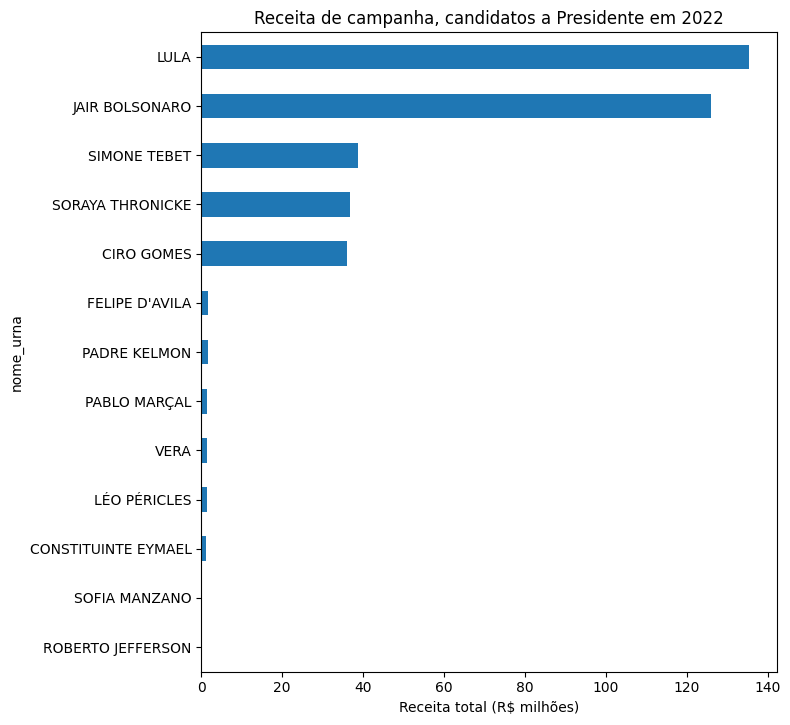

In [9]:
import matplotlib.pyplot as plt

df = analysis.panorama(repo, anos=[ANO_ANALISE]).dropna(subset=["total_recebido"])
if df.empty:
    print("Sem dados financeiros para", ANO_ANALISE)
else:
    df = df.sort_values("total_recebido")
    ax = (df.set_index("nome_urna")["total_recebido"] / 1e6).plot.barh(figsize=(8, 0.45 * len(df) + 1.5))
    ax.set_xlabel("Receita total (R$ milhões)")
    ax.set_title(f"Receita de campanha, candidatos a Presidente em {ANO_ANALISE}")
    plt.tight_layout(); plt.show()

## 8. Exportação

Gera um CSV por tabela/view (UTF-8 com BOM, abre direto no Excel) em `data/csv/`. O arquivo `.db` também pode ser aberto com qualquer cliente SQLite (DBeaver, DB Browser) ou por `pandas.read_sql_query`.

In [10]:
[str(p) for p in repo.export_csv("data/csv")]

['data/csv/eleicoes.csv',
 'data/csv/candidatos.csv',
 'data/csv/financeiro_resumo.csv',
 'data/csv/despesas_categoria.csv',
 'data/csv/doadores.csv',
 'data/csv/coleta_log.csv',
 'data/csv/vw_candidatos_financeiro.csv',
 'data/csv/vw_doadores_candidatos.csv']